In [ ]:
import os
import sys
import re
import math
from copy import copy
import umap

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

import scipy

import anndata
import scanpy as sc
import scanpy.external as sce
# import squidpy as sq
# import gseapy
import squidpy as sq

import warnings
warnings.filterwarnings('ignore')

from matplotlib.pyplot import rc_context
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0,0,0,0), dpi=50, dpi_save=600)
sns.set_style({'axes.grid' : False})

# os.environ["R_HOME"] = "/home/xuq44/scratch/miniconda3/envs/scr/lib/R" 
# import rpy2
# from rpy2.robjects import r


# %load_ext rpy2.ipython


In [32]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'
fig_dir = f'{project_dir}/figures/'

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'

gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

mpl_reds = copy(mpl.cm.Reds)
mpl_reds.set_under("lightgray")

plate_level_all['2']='#F69D43'
plate_level_all['3']='#E42859'
plate_level_all['7']='#a3e3af'
plate_level_all['1']='#c76cde'


In [5]:
adata = sc.read_h5ad("/home/xuquan/projects/pdac/merscope/tumoroid/all_merscope_tumoroid.h5ad")


In [17]:
adata

AnnData object with n_obs × n_vars = 69870 × 300
    obs: 'label', 'area', 'centroid-0', 'centroid-1', 'region', 'rep', 'batch', 'n_genes_by_counts', 'total_counts', 'volume_factor', 'leiden', 'sam'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'region_colors', 'umap', 'wilcoxon', 'rep_colors', 'spatial_neighbors'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

In [20]:
# sq.gr.spatial_neighbors(adata)
sq.gr.nhood_enrichment(adata, cluster_key="leiden")


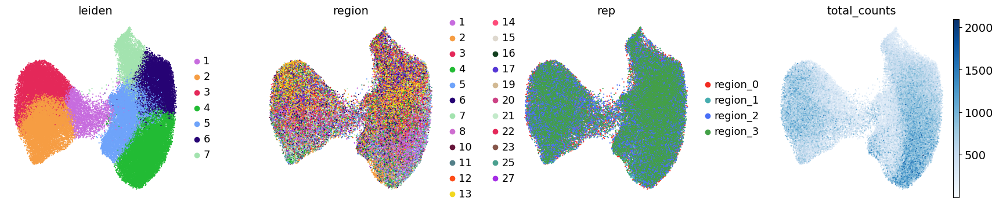

In [33]:
sc.pl.embedding(adata, 'umap', color=['leiden', 'region', 'rep', 'total_counts'],
                    vmin=0.01, color_map=gns, ncols=4, frameon=False, size=10, wspace=0.3,
                    palette=plate_level_all, save='merscope_org_cluster.pdf')

In [36]:
sams=[]
for i,j in zip(adata.obs.region,adata.obs.batch):
    if int(i)<10:
        sams.append(f'R0{i}_{int(j)+1}')
    else:
        sams.append(f'R{i}_{int(j)+1}')
        
adata.obs['sam'] = sams


In [40]:
ct_forplot.div(ct_forplot.sum(axis=1), axis=0).sort_index()

leiden,1,2,3,4,5,6,7
sam,,,,,,,
R01_1,0.045455,0.164242,0.105455,0.167879,0.219394,0.240606,0.056970
R01_2,0.052275,0.175473,0.103419,0.353207,0.131676,0.150325,0.033625
R01_3,0.049860,0.212079,0.116573,0.104635,0.185393,0.250000,0.081461
R01_4,0.032718,0.189597,0.029362,0.470638,0.166107,0.091443,0.020134
R02_2,0.033133,0.192102,0.104083,0.362450,0.130522,0.118474,0.059237
R02_4,0.029821,0.171968,0.129225,0.333002,0.173956,0.098410,0.063618
R03_4,0.058333,0.181250,0.076563,0.194792,0.190625,0.167187,0.131250
R04_2,0.038956,0.110621,0.077545,0.237780,0.219037,0.227122,0.088938
R04_4,0.036424,0.159768,0.097682,0.281457,0.223510,0.140728,0.060430


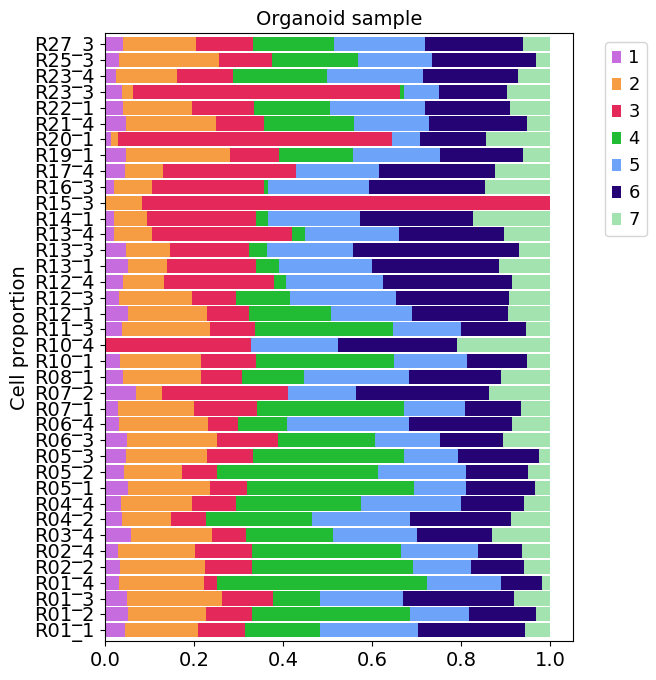

In [43]:
ct_forplot = adata.obs.groupby(['sam','leiden']).count()['area'].\
                    reset_index().set_index('sam').\
                    pivot(columns='leiden',values='area')
ct_forplot = ct_forplot.div(ct_forplot.sum(axis=1), axis=0).sort_index()[['1','2','3','4','5','6','7']]

fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharey=True)
ct_forplot.plot(kind='barh', stacked=True, figsize=(6, 8), width=0.9,
                color=[plate_level_all[col] for col in ct_forplot.columns],
                ax=ax)
ax.set_title("Organoid sample")
ax.set_ylabel("Cell proportion")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
fig.savefig(f'{fig_dir}/merscope_org_cluster_cell_proportion.pdf')


In [34]:
adatax1 = adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')]
adatax2 = adata[(adata.obs.rep=='region_0')&(adata.obs.region=='7')]
adatax3 = adata[(adata.obs.rep=='region_0')&(adata.obs.region=='10')]
adatax4 = adata[(adata.obs.rep=='region_0')&(adata.obs.region=='19')]

sq.gr.spatial_neighbors(
    adatax1,
    coord_type="generic",
    spatial_key="spatial",
    delaunay=True,
    percentile=98,
)

sq.gr.spatial_neighbors(
    adatax2,
    coord_type="generic",
    spatial_key="spatial",
    delaunay=True,
    percentile=98,
)

sq.gr.spatial_neighbors(
    adatax3,
    coord_type="generic",
    spatial_key="spatial",
    delaunay=True,
    percentile=98,
)

sq.gr.spatial_neighbors(
    adatax4,
    coord_type="generic",
    spatial_key="spatial",
    delaunay=True,
    percentile=98,
)



INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  


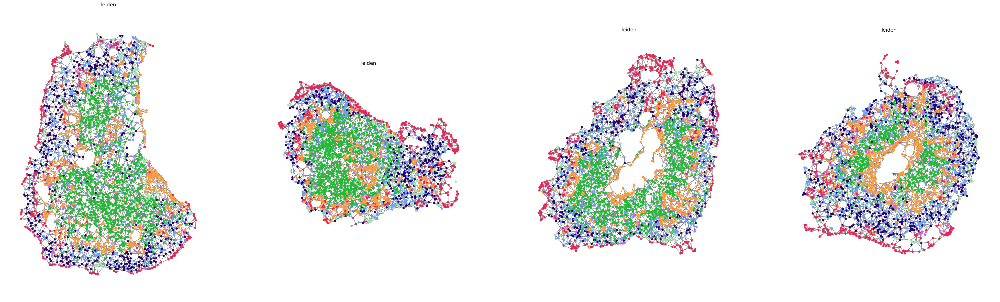

In [35]:
fig, axs = plt.subplots(1, 4, figsize=(50, 15))

size=100


sq.pl.spatial_scatter(
    adatax1,
    color="leiden",
    shape=None,
    size=size,
    connectivity_key="spatial_connectivities",
    edges_width=1,
    legend_loc=None,
    frameon=False,
#     palette=plate_level_all,
    ax=axs[0],
)


sq.pl.spatial_scatter(
    adatax2,
    color="leiden",
    shape=None,
    size=size,
    connectivity_key="spatial_connectivities",
    edges_width=1,
    legend_loc=None,
    frameon=False,
#     palette=plate_level_all,
    ax=axs[1],
)

sq.pl.spatial_scatter(
    adatax3,
    color="leiden",
    shape=None,
    size=size,
    connectivity_key="spatial_connectivities",
    edges_width=1,
    legend_loc=None,
    frameon=False,
#     palette=plate_level_all,
    ax=axs[2],
)

sq.pl.spatial_scatter(
    adatax4,
    color="leiden",
    shape=None,
    size=size,
    connectivity_key="spatial_connectivities",
    edges_width=1,
    legend_loc=None,
    frameon=False,
#     palette=plate_level_all,
    ax=axs[3],
)



fig.savefig(f"{fig_dir}/merscope_org_sp.pdf", bbox_inches="tight")


### tissue corr

In [77]:
def get_sim(adata, ref='epithelial'):
#     sc.tl.leiden(adata, resolution=2, key_added='leiden_2')
#     adata_leiden_mean = scsim.get_bulk_exp(adata, 'leiden_2', layer='var')
    adata_leiden_mean = scsim.get_bulk_exp(adata, 'leiden', layer='var')
    
#     adata_leiden_mean = adata.to_df().T
    res_dir = 'run_20241130_scp'
    adata_ref = sc.read_h5ad(f"{project_dir}/results/{res_dir}/{ref}/pdac_scpoli_late_final2.h5ad")
    ref_ct_mean = scsim.get_bulk_exp(adata_ref, 'celltype2', layer='var')

    inter_genes = list(set(adata_leiden_mean.index) & set(ref_ct_mean.index))

    adata_leiden_mean = adata_leiden_mean.loc[inter_genes]
    ref_ct_mean = ref_ct_mean.loc[inter_genes]

    corr = scsim.correlation_map(adata_leiden_mean.T, ref_ct_mean.T)

    # corr = scsim.correlation_map(scsim.rankMatrix(adata_leiden_mean.T), 
    #                        scsim.rankMatrix(celltype2_ct_mean.T))

    all_corr_df = pd.DataFrame(corr)
    all_corr_df = all_corr_df.set_axis(ref_ct_mean.columns, axis=1)
    all_corr_df = all_corr_df.set_axis(adata_leiden_mean.columns)
    all_corr_df = all_corr_df.fillna(0).T
    
    return all_corr_df


In [78]:
epi_corr_df0 = get_sim(adata, ref='epithelial')
mes_corr_df0 = get_sim(adata, ref='mesenchyme')



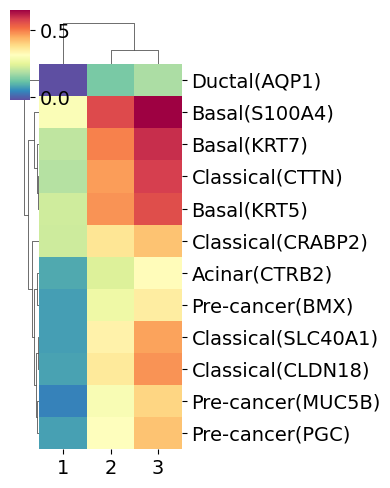

In [79]:
epi_corr_df = epi_corr_df0[['1','2','3']]

sns.clustermap(epi_corr_df, 
#                standard_scale=1, 
               cmap='Spectral_r', dendrogram_ratio=0.1, colors_ratio=0.01,
              figsize=(4, 5))

# plt.savefig(f'{fig_dir}/merscope_org_cluster_sim_cancer.pdf')


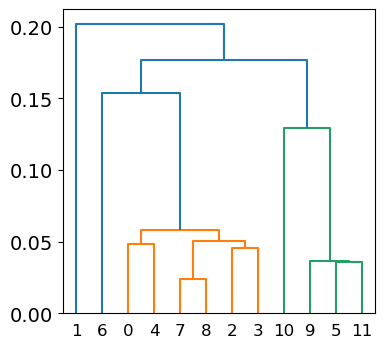

In [108]:
_ = dendrogram(link2)


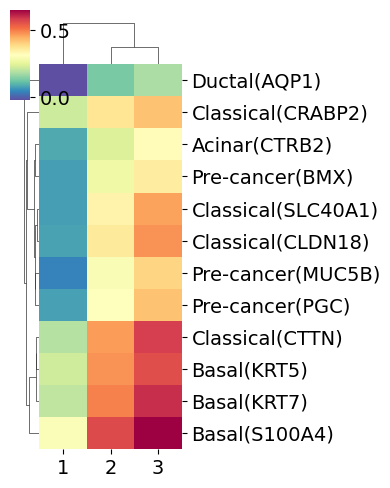

In [111]:
link1 = linkage(epi_corr_df.T)
link2 = linkage(epi_corr_df)
# link1[1][[0,1]]=link1[1][[1,0]]
# link1[6][[0,1]]=link1[6][[1,0]]
# link2[4][[0,1]]=link2[4][[1,0]]
link2[9][[0,1]]=link2[9][[1,0]]
link2[7][[0,1]]=link2[7][[1,0]]
link2[2][[0,1]]=link2[2][[1,0]]

sns.clustermap(epi_corr_df, 
               col_linkage=link1, 
               row_linkage=link2, 
               row_cluster=True, col_cluster=True,
               cmap='Spectral_r', dendrogram_ratio=0.1, colors_ratio=0.01,
               figsize=(4,5))

plt.savefig(f'{fig_dir}/merscope_org_cluster_sim_cancer.pdf')



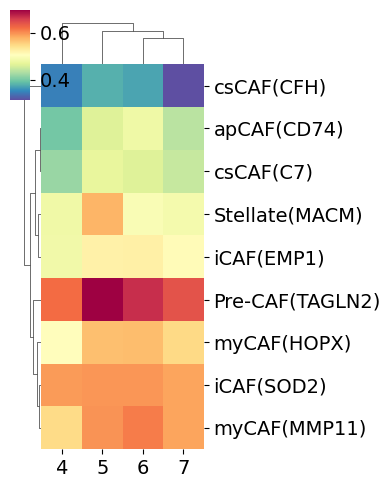

In [93]:
mes_corr_df = mes_corr_df0[['4','5','6','7']]

sns.clustermap(mes_corr_df, 
#                standard_scale=1, 
               cmap='Spectral_r', dendrogram_ratio=0.1, colors_ratio=0.01,
              figsize=(4, 5))

# plt.savefig(f'{fig_dir}/merscope_org_cluster_sim_caf.pdf')


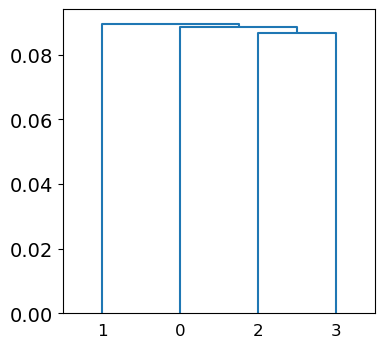

In [100]:
_ = dendrogram(link1)


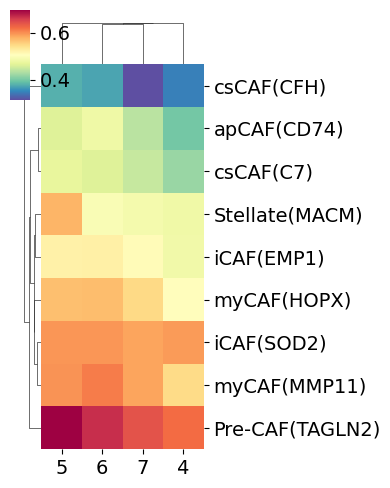

In [102]:
link1 = linkage(mes_corr_df.T)
link2 = linkage(mes_corr_df)
link1[1][[0,1]]=link1[1][[1,0]]
# link1[6][[0,1]]=link1[6][[1,0]]
# link2[4][[0,1]]=link2[4][[1,0]]
link2[6][[0,1]]=link2[6][[1,0]]

sns.clustermap(mes_corr_df, 
               col_linkage=link1, 
               row_linkage=link2, 
               row_cluster=True, col_cluster=True,
               cmap='Spectral_r', dendrogram_ratio=0.1, colors_ratio=0.01,
               figsize=(4,5))

plt.savefig(f'{fig_dir}/merscope_org_cluster_sim_caf.pdf')



In [61]:
# mes_corr_df

### plot genes

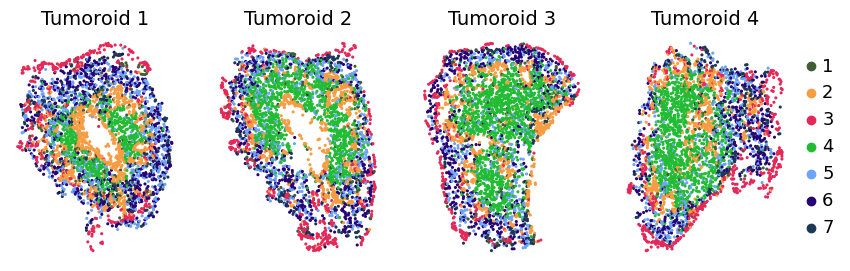

In [11]:
fig, axs = plt.subplots(1, 4, figsize=(10, 3))

size=20

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='19')], 'spatial', 
                color=['leiden'], legend_loc=None, title='Tumoroid 1',
                frameon=False, size=size, palette=plate_level_all, show=False, ax=axs[0])

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='10')], 'spatial', 
                color=['leiden'], show=False,legend_loc=None,
                vmin=0.01, frameon=False, size=size, wspace=0.1,
                title='Tumoroid 2',
                palette=plate_level_all, ax=axs[1])

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')], 'spatial', 
                color=['leiden'],  show=False,legend_loc=None,
                vmin=0.01, frameon=False, size=size, wspace=0.1,
                title='Tumoroid 3',
                palette=plate_level_all, ax=axs[2])

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='7')], 'spatial', 
                color=['leiden'],  show=False, title='Tumoroid 4',
                vmin=0.01, frameon=False, size=size, wspace=0.1,
                palette=plate_level_all, ax=axs[3])

fig.savefig(f"{fig_dir}/merscope_org_sp.pdf", bbox_inches="tight")


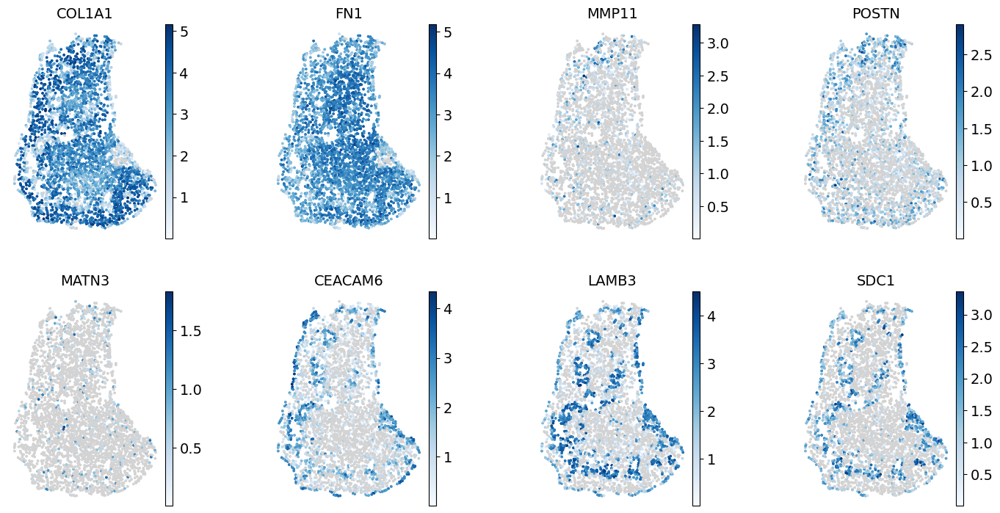

In [155]:
sq.pl.spatial_scatter(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')], shape=None,
                    color=['COL1A1', 'FN1', 'MMP11','POSTN','MATN3','CEACAM6', 'LAMB3','SDC1'], 
                    vmin=0.01, ncols=4, frameon=False, size=10, wspace=0.1, cmap=gns,
                    palette=plate_level_all, save='merscope_org_markers.pdf')


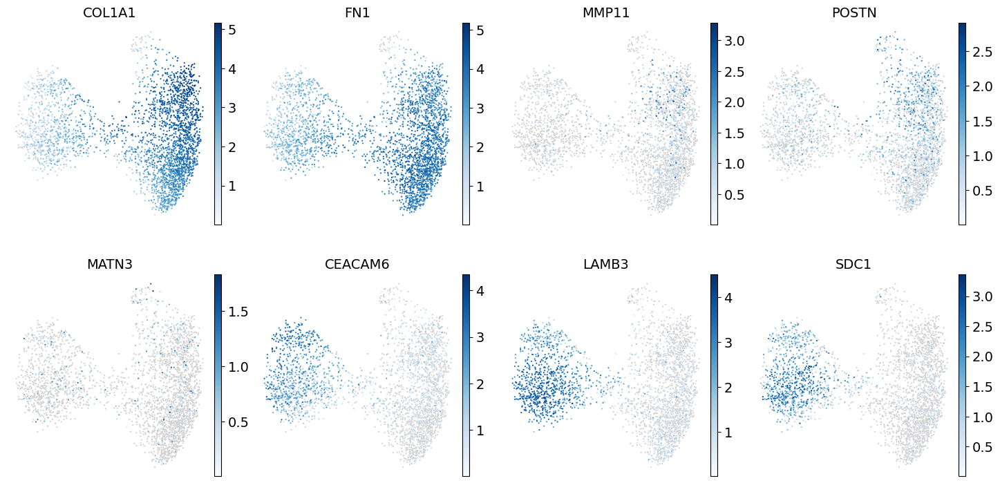

In [159]:
sc.pl.umap(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')], 
                    color=['COL1A1', 'FN1', 'MMP11','POSTN','MATN3','CEACAM6', 'LAMB3','SDC1'], 
                    vmin=0.01, ncols=4, frameon=False, size=10, wspace=0.1, cmap=gns,
                    palette=plate_level_all, save='merscope_org_markers2.pdf')


### C23 compare

In [50]:
adata_c23 = adata[adata.obs.leiden.isin(['2','3'])].copy()
sc.tl.rank_genes_groups(adata_c23, 'leiden', method='wilcoxon', key_added = "wilcoxon")


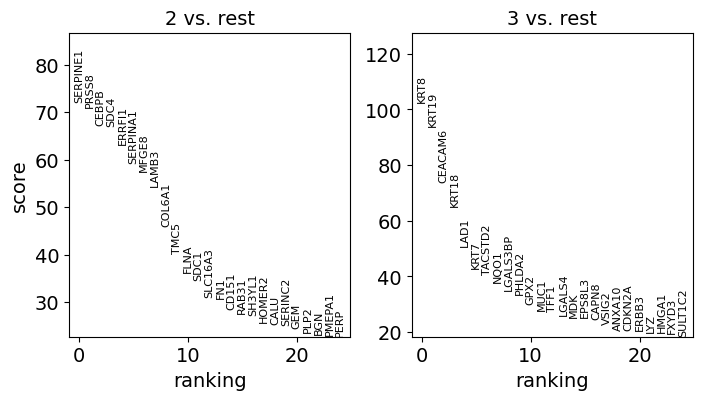

In [51]:
sc.pl.rank_genes_groups(adata_c23, n_genes=25, sharey=False, key="wilcoxon")


In [52]:
wc_c23 = sc.get.rank_genes_groups_df(adata_c23, group='3', key='wilcoxon')
wc_c23['padj']=[1e-300 if i==0 else i for i in wc_c23.pvals_adj]
wc_c23['-log10padj'] = -np.log10(wc_c23.padj)


<Axes: xlabel='logfoldchanges', ylabel='-log10padj'>

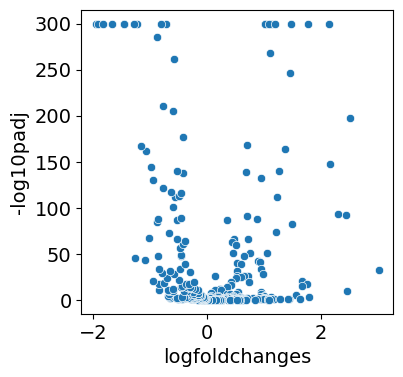

In [53]:
sns.scatterplot(wc_c23, x='logfoldchanges', y='-log10padj')

In [77]:
%%R -i wc_c23 -i fig_dir
library(EnhancedVolcano)
library(stringr)


p <- EnhancedVolcano(wc_c23,
    lab = wc_c23$names,
    x = 'logfoldchanges',
    y = 'pvals_adj',
    pCutoff = 10e-100,
    FCcutoff = 1,
    colAlpha = 4/5,
    drawConnectors = TRUE)

pdf(str_c(fig_dir,'/merscope_org_c23_volcano.pdf'), width=4, height=6)
print(p)
dev.off()

png 
  2 


In [89]:
wc_c23.head(20).names.tolist()+wc_c23.tail(20).names.tolist()

['KRT8',
 'KRT19',
 'CEACAM6',
 'KRT18',
 'LAD1',
 'KRT7',
 'TACSTD2',
 'NQO1',
 'LGALS3BP',
 'PHLDA2',
 'GPX2',
 'MUC1',
 'TFF1',
 'LGALS4',
 'MDK',
 'EPS8L3',
 'CAPN8',
 'VSIG2',
 'ANXA10',
 'CDKN2A',
 'SERINC2',
 'CALU',
 'HOMER2',
 'SH3YL1',
 'RAB31',
 'CD151',
 'FN1',
 'SLC16A3',
 'SDC1',
 'FLNA',
 'TMC5',
 'COL6A1',
 'LAMB3',
 'MFGE8',
 'SERPINA1',
 'ERRFI1',
 'SDC4',
 'CEBPB',
 'PRSS8',
 'SERPINE1']

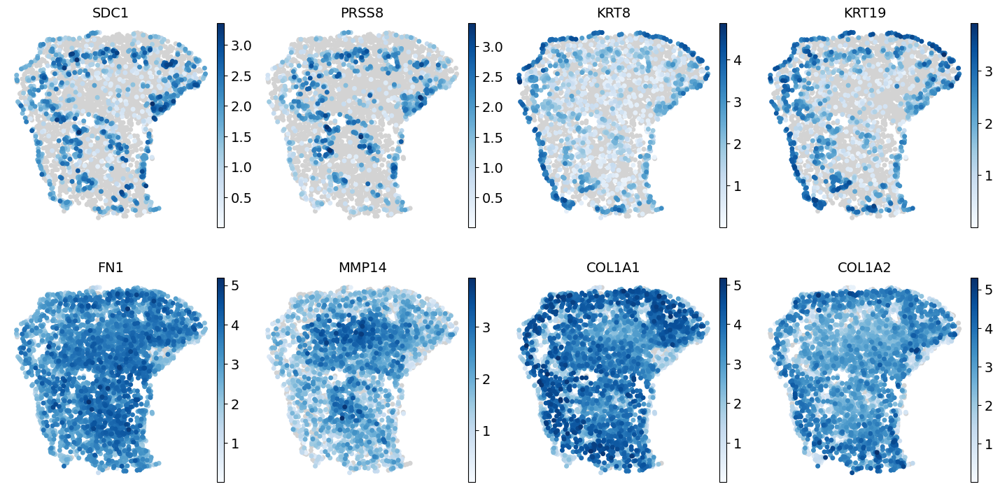

In [79]:

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')], 'spatial', 
                color=['SDC1','PRSS8','KRT8','KRT19','FN1','MMP14','COL1A1','COL1A2'], legend_loc=None,
                vmin=0.01, ncols=4, frameon=False, size=100, wspace=0.1, cmap=gns,
                save='merscope_org_r0_5_marker.pdf')


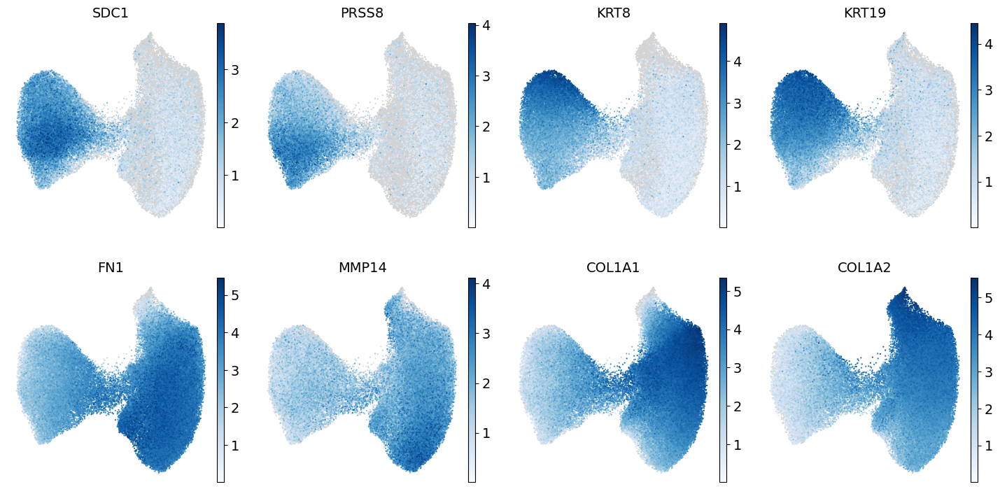

In [93]:

sc.pl.embedding(adata, 'umap', 
                color=['SDC1','PRSS8','KRT8','KRT19','FN1','MMP14','COL1A1','COL1A2'], legend_loc=None,
                vmin=0.01, ncols=4, frameon=False, size=10, wspace=0.1, cmap=gns,
                save='merscope_org_r0_5_marker.pdf')


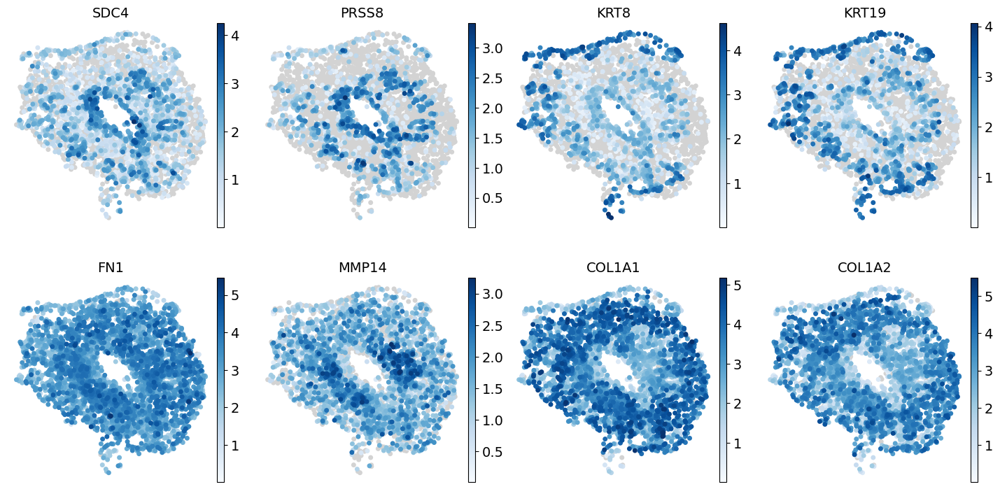

In [73]:

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='19')], 'spatial', 
                color=['SDC4','PRSS8','KRT8','KRT19','FN1','MMP14','COL1A1','COL1A2'], legend_loc=None,
                vmin=0.01, ncols=4, frameon=False, size=100, wspace=0.1, cmap=gns,
                save='merscope_org_r0_19_marker.pdf')


### C46

In [70]:
adata_c46 = adata[adata.obs.leiden.isin(['4','5','6','7'])].copy()
adata_c46.obs.loc[adata_c46.obs.leiden.isin(['5','6','7']), 'leiden'] = '6'
adata_c46.obs.leiden = adata_c46.obs.leiden.astype(str)
sc.tl.rank_genes_groups(adata_c46, 'leiden', method='wilcoxon', key_added = "wilcoxon")
wc_c46 = sc.get.rank_genes_groups_df(adata_c46, group='6', key='wilcoxon')


In [75]:
%%R -i wc_c46
library(EnhancedVolcano)

p <- EnhancedVolcano(wc_c46,
    lab = wc_c46$names,
    x = 'logfoldchanges',
    y = 'pvals_adj',
    pCutoff = 10e-100,
    FCcutoff = 1,
    colAlpha = 4/5,
    drawConnectors = TRUE)

pdf(str_c(fig_dir,'/merscope_org_c46_volcano.pdf'), width=4, height=6)
print(p)
dev.off()

png 
  2 


In [76]:
wc_c46

,names,scores,logfoldchanges,pvals,pvals_adj
0,COL1A2,110.000381,1.181056,0.0,0.0
1,COL3A1,106.595627,1.558584,0.0,0.0
2,MFAP4,81.616257,2.036069,0.0,0.0
3,COL1A1,73.810783,0.830112,0.0,0.0
4,POSTN,62.277012,1.568538,0.0,0.0
...,...,...,...,...,...
295,CEBPB,-78.246033,-1.590678,0.0,0.0
296,FN1,-80.384102,-0.907420,0.0,0.0
297,MMP14,-108.026886,-1.446242,0.0,0.0
298,LOX,-109.812950,-2.148478,0.0,0.0


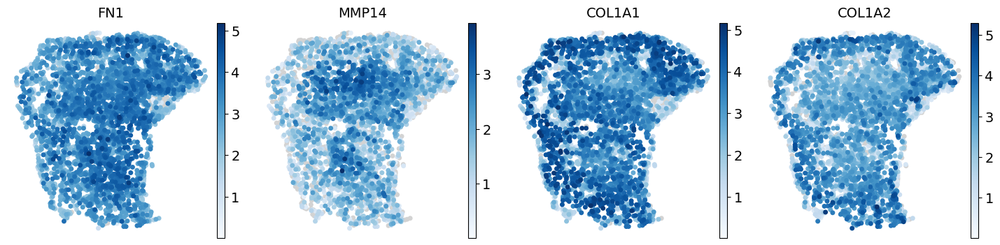

In [80]:

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')], 'spatial', 
                color=['FN1','MMP14','COL1A1','COL1A2'], legend_loc=None,
                vmin=0.01, ncols=4, frameon=False, size=100, wspace=0.1, cmap=gns,
                                save='merscope_org_r0_5_marker2.pdf')



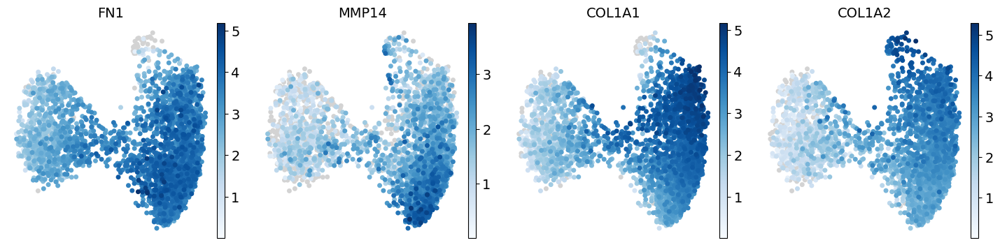

In [92]:

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='5')], 'umap', 
                color=['FN1','MMP14','COL1A1','COL1A2'], legend_loc=None,
                vmin=0.01, ncols=4, frameon=False, size=100, wspace=0.1, cmap=gns,
                                save='merscope_org_r0_5_marker2.pdf')



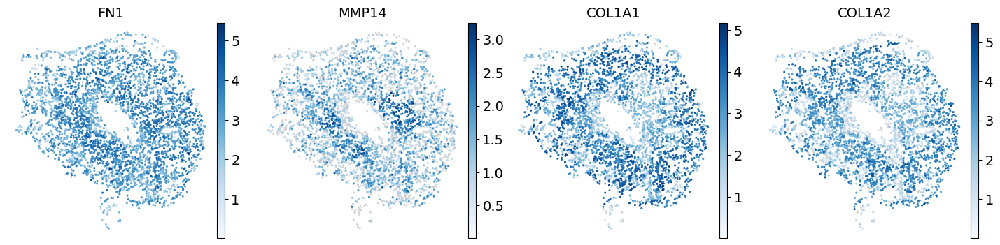

In [61]:

sc.pl.embedding(adata[(adata.obs.rep=='region_0')&(adata.obs.region=='19')], 'spatial', 
                color=['FN1','MMP14','COL1A1','COL1A2'], legend_loc=None,
                vmin=0.01, ncols=4, frameon=False, size=20, wspace=0.1, cmap=gns)


In [90]:
wc_c46.head(20).names.tolist()+wc_c46.tail(20).names.tolist()

['COL1A2',
 'COL3A1',
 'MFAP4',
 'COL1A1',
 'POSTN',
 'OLFML3',
 'GEM',
 'IGFBP5',
 'THBS2',
 'PPIC',
 'TSPAN3',
 'TAGLN',
 'MMP11',
 'MYL9',
 'CALD1',
 'CEACAM6',
 'COL6A3',
 'COL12A1',
 'SLC4A4',
 'EMILIN1',
 'MORF4L2',
 'VKORC1',
 'CERCAM',
 'CHPF',
 'COL6A2',
 'ERRFI1',
 'LRP1',
 'MARCKS',
 'DCN',
 'FKBP10',
 'SERPINH1',
 'SDC4',
 'SLC16A3',
 'COL5A1',
 'FBN1',
 'CEBPB',
 'FN1',
 'MMP14',
 'LOX',
 'SERPINE1']